# EDA for Feature Discovery: Battery SOH under Unseen Conditions

**Goal:** decide *which features to use* for SOH regression / health classification, with an eye on the
project's real question: **do they still work for unseen cells and unseen operating profiles?**

**Unit of analysis.** SOH is only measured during the Reference Test Protocol (RTP), roughly every three weeks.
So one row = one RTP of one cell. Features come from (a) the RTP itself (health indicators measured on the cell),
(b) the usage history before it (throughput, time, temperature), and (c) the load-profile design parameters.

**Target.** `SOH = 1C discharge capacity (4.2 V → 2.5 V) / capacity at the cell's first RTP@25 °C`.
Only RTP@25 °C rows get an SOH value (see Section 2 for why).

Features are produced by [`src/features.py`](../src/features.py). Run `python -m src.features data/raw results/rtp_features.csv` first.

> **Correction to the pilot notebook.** `battery_data_processing_intermediate_2_009.ipynb` pairs `info` row *i* with
> the *i*-th sorted test group. The `info` rows are not in test order, so many tests get the wrong label
> (e.g. a 22-day L03 ageing run labelled RTP25). The correct key is `test_XXXX ↔ info.idtest == XXXX`, verified because
> every test's duration matches the gap to the next start time. Its SOH proxy (max discharge counter over a whole test)
> also used an aborted test as reference (4.09 Ah > the 3.25 Ah rating). Both are fixed in `src/features.py`.

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, h5py
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import load_test, read_info, step_blocks, C_NOM

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RAW = ROOT / "data" / "raw"

df_all = pd.read_csv(ROOT / "results" / "rtp_features.csv", dtype={"cell_id": str})
df = df_all[df_all.rtp_T_set == 25].dropna(subset=["SOH"]).reset_index(drop=True)
print("all RTP rows:", df_all.shape, "| RTP@25C rows with SOH:", df.shape)

all RTP rows: (422, 75) | RTP@25C rows with SOH: (306, 75)


## 1. What data do we have?

In [2]:
overview = (df.groupby(["cell_id", "profile"])
              .agg(n_rtp=("SOH", "size"), days=("days_since_start", "max"), EFC=("cum_EFC", "max"),
                   SOH_end=("SOH", "min"), T_set=("lp_T_set", "first"), CC=("lp_CC", "first"),
                   ADC=("lp_ADC", "first"), SoC=("lp_SoC", "first"), dSoC=("lp_dSoC", "first"))
              .round(1).reset_index())
display(overview)
print(f"{df.cell_id.nunique()} cells, {df.profile.nunique()} profiles, {len(df)} labelled rows")

,cell_id,profile,n_rtp,days,EFC,SOH_end,T_set,CC,ADC,SoC,dSoC
0,2_009,L03,21,530.8,1561.9,87.2,40.0,0.2,2.0,25.0,2.5
1,2_010,L03,21,530.8,1585.8,89.7,40.0,0.2,2.0,25.0,2.5
2,2_012,L35,22,530.8,1231.8,51.5,40.0,0.2,2.0,55.0,80.0
3,2_027,L208,22,530.8,434.4,92.8,0.0,0.0,1.5,55.0,2.5
4,2_030,L210,22,530.7,396.3,87.7,0.0,0.0,0.9,85.0,20.0
5,2_033,L211,22,530.7,412.0,70.2,0.0,0.0,1.5,40.0,50.0
6,2_058,L213,22,530.8,576.6,78.4,30.0,0.0,1.5,70.0,50.0
7,2_067,V212,21,509.9,707.3,47.0,NaN,NaN,NaN,NaN,NaN
8,2_076,L223,6,140.0,356.4,40.1,20.0,0.5,0.3,70.0,50.0
9,2_092,L202,22,530.8,8.3,88.2,45.0,0.0,0.0,15.0,0.0


15 cells, 14 profiles, 306 labelled rows


**Read this table before modelling.** Each cell contributes only ~5–25 labelled points, and the profiles differ a lot
in how far the cells degrade. Calendar-ageing cells (L2xx with zero current) barely accumulate equivalent full cycles (EFC). That is
exactly why a random row split looks optimistic: neighbouring RTPs of the same cell are nearly identical.

## 2. Target sanity checks
### 2a. Why SOH must use RTP@25 °C only

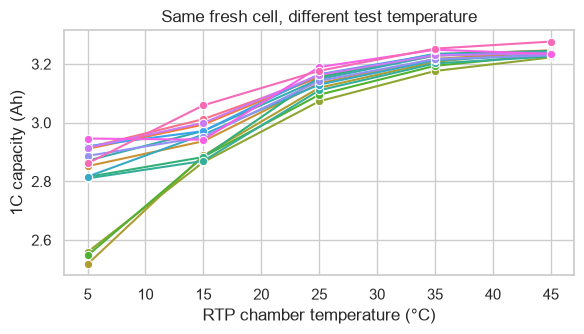

            mean    std
rtp_T_set              
5          2.810  0.145
15         2.946  0.058
25         3.141  0.031
35         3.221  0.020
45         3.239  0.013


In [3]:
init = df_all[df_all.rtp_index <= 1].copy()          # initial characterisation RTPs (before ageing)
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.lineplot(data=init, x="rtp_T_set", y="cap_1C_Ah", hue="cell_id", marker="o", ax=ax, legend=False)
ax.set(xlabel="RTP chamber temperature (°C)", ylabel="1C capacity (Ah)",
       title="Same fresh cell, different test temperature")
plt.tight_layout(); plt.savefig(FIG / "capacity_vs_test_temperature.png", dpi=150); plt.show()
print(init.groupby("rtp_T_set").cap_1C_Ah.agg(["mean", "std"]).round(3))

A fresh cell shows roughly 10 % less capacity at 5 °C than at 45 °C. If the RTP05/15/35/45 tests were mixed in, temperature
would look like "ageing". So: **SOH is defined on RTP@25 °C only**, and `rtp_T_set` must never be used as a feature for SOH.

### 2b. SOH trajectories: by time and by charge throughput

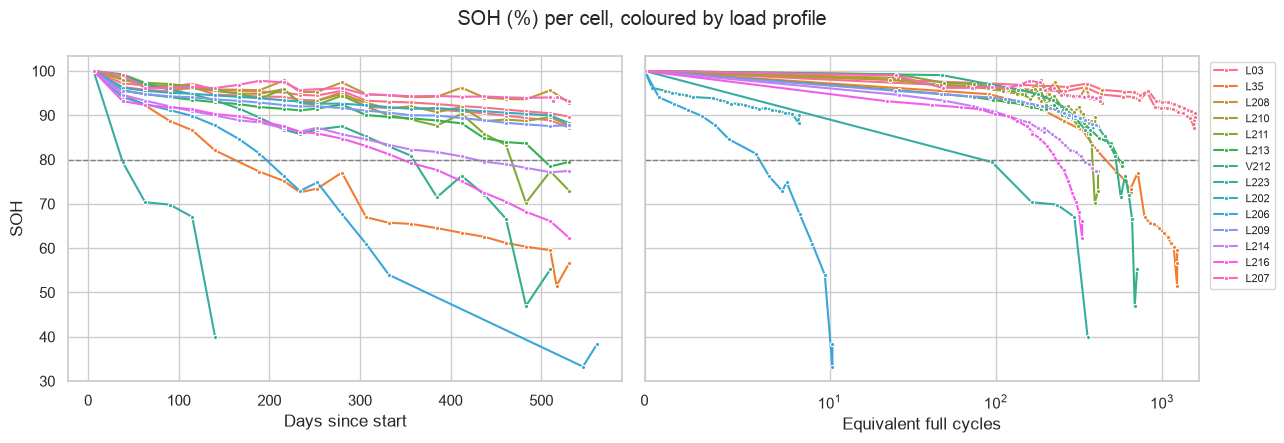

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, x, lab in [(axes[0], "days_since_start", "Days since start"), (axes[1], "cum_EFC", "Equivalent full cycles")]:
    sns.lineplot(data=df, x=x, y="SOH", hue="profile", units="cell_id", estimator=None, marker=".", ax=ax)
    ax.axhline(80, ls="--", c="grey", lw=1); ax.set_xlabel(lab)
axes[1].set_xscale("symlog", linthresh=10); axes[1].set_xlim(left=0)
axes[0].get_legend().remove(); axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.suptitle("SOH (%) per cell, coloured by load profile"); plt.tight_layout()
plt.savefig(FIG / "soh_trajectories.png", dpi=150); plt.show()

Observations to look for:
* **Same EFC, very different SOH across profiles.** Throughput alone does not explain degradation; operating conditions
  (temperature, SOC window) matter. This is the generalization challenge in one picture.
* Calendar cells lose capacity with ~0 EFC, so **time** must be a feature alongside throughput.
* Small upward bumps (capacity recovery after rests) are measurement noise that no model can predict.

### 2c. Target distribution and candidate health classes

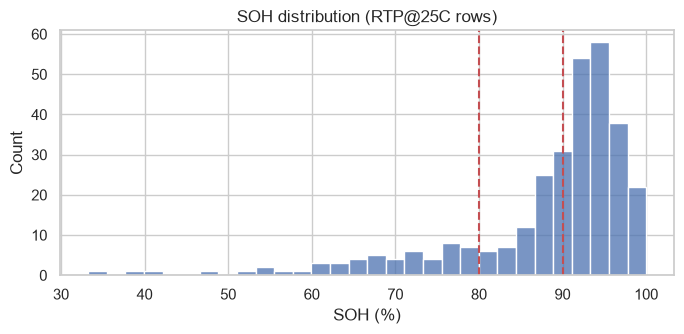

A: 90/80 {'Healthy': 187, 'Degraded': 66, 'EOL-risk': 53} | cells reaching EOL-risk: 8
B: 95/85 {'Healthy': 71, 'Degraded': 165, 'EOL-risk': 70} | cells reaching EOL-risk: 8


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(df.SOH, bins=30, ax=ax)
for t in (90, 80): ax.axvline(t, c="r", ls="--")
ax.set(title="SOH distribution (RTP@25C rows)", xlabel="SOH (%)")
plt.tight_layout(); plt.savefig(FIG / "soh_hist.png", dpi=150); plt.show()

bins_ = {"A: 90/80": [0, 80, 90, 200], "B: 95/85": [0, 85, 95, 200]}
for name, b in bins_.items():
    cls = pd.cut(df.SOH, b, labels=["EOL-risk", "Degraded", "Healthy"], right=False)
    print(name, cls.value_counts().reindex(["Healthy", "Degraded", "EOL-risk"]).to_dict(),
          "| cells reaching EOL-risk:", df.loc[cls == "EOL-risk", "cell_id"].nunique())

Pick the class thresholds from these counts. Common automotive practice is **80 % = end of life**. The dataset authors
used **70 %**, so most cells never reach it. If the EOL-risk class is tiny or comes from only 1–2 cells, either use
project-defined thresholds (option B) or report classification as exploratory. Recall on that class under
leave-cell-out would rest on almost no cells.

## 3. Looking at the raw signals: what changes as the cell ages?

example cell: 2_095


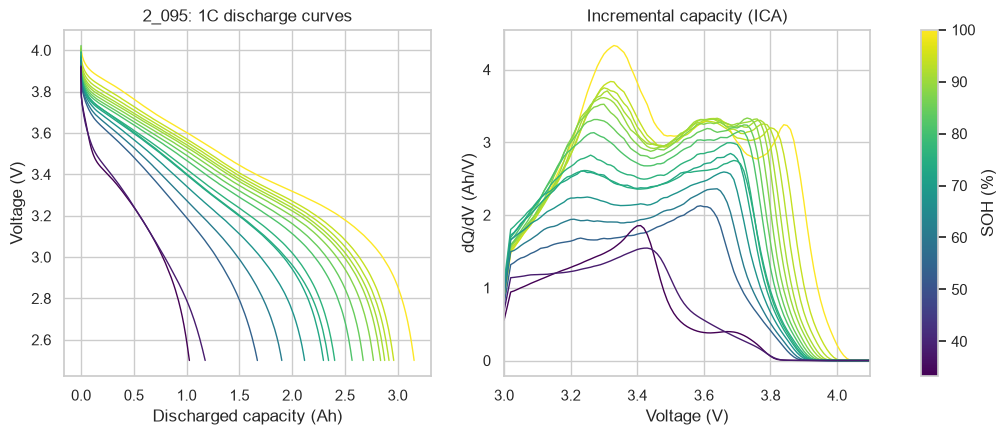

In [6]:
CELL = df.groupby("cell_id").SOH.min().idxmin()      # the most-degraded cell gives the clearest picture
print("example cell:", CELL)
with h5py.File(RAW / f"{CELL}.h5") as f:
    info = read_info(f)
    rtps = info[info.expname == "RTP25"]
    soh_map = df[df.cell_id == CELL].set_index("idtest").SOH
    curves = []
    for m in rtps.itertuples():
        if m.idtest not in soh_map.index: continue
        d = load_test(f["tests"][m.group]); b = step_blocks(d)
        full = b[(b.I.between(-1.1*C_NOM, -0.9*C_NOM)) & (b.V1 < 2.6) & (b.dur > 900)].iloc[-1]
        s = slice(int(full.a), int(full.b) + 1)
        curves.append((soh_map[m.idtest], d["dischargecap"][s] - d["dischargecap"][int(full.a)], d["voltage"][s]))

cmap = plt.cm.viridis
norm = plt.Normalize(min(c[0] for c in curves), 100)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for soh, Q, V in curves:
    axes[0].plot(Q, V, color=cmap(norm(soh)), lw=1)
    grid = np.arange(3.0, 4.15, 0.01)
    o = np.argsort(V); Vu, k = np.unique(V[o], return_index=True)
    ic = -np.gradient(np.interp(grid, Vu, Q[o][k]), 0.01)
    axes[1].plot(grid, np.convolve(ic, np.ones(5)/5, "same"), color=cmap(norm(soh)), lw=1)
axes[0].set(xlabel="Discharged capacity (Ah)", ylabel="Voltage (V)", title=f"{CELL}: 1C discharge curves")
axes[1].set(xlabel="Voltage (V)", ylabel="dQ/dV (Ah/V)", title="Incremental capacity (ICA)", xlim=(3.0, 4.1))
fig.colorbar(plt.cm.ScalarMappable(norm, cmap), ax=axes, label="SOH (%)")
plt.savefig(FIG / "discharge_and_ica_curves.png", dpi=150); plt.show()

* The discharge curve **shortens** (capacity loss) and **drops lower** (more polarization / resistance). That gives the
  partial-window capacity features (`dis1C_Q_3.8_3.5V`, `dis1C_t_to_3.6V_s`) and `dis1C_meanV`.
* The ICA peak **shrinks and shifts**, which motivates `ica_p1..p3_height` and `ica_p1..p3_V` (the ~3.3 V and ~3.85 V peaks change most). These are classic
  loss-of-active-material indicators.

## 4. Feature groups and the leakage question

Every RTP-derived feature is measured in the *same* test as the target. Some of them are just the capacity
measured another way, and using them would be target leakage. The features are grouped by **what a real system could know**:

In [7]:
GROUPS = {
    "LEAKY (exclude)": ["cap_1C_Ah", "dis1C_energy_Wh", "cap_1C_spread_Ah", "cap_ref_Ah"],
    "Partial-capacity HI": ["dis1C_Q_3.8_3.5V", "dis1C_t_to_3.6V_s", "dis_C3_CC_Ah", "chg_CC_Ah",
                            "chg_CC_time_s", "chg_CV_Ah", "ica_area_3.4_3.8V"],
    "Shape / resistance HI": ["R_1p13C_10s_mean", "R_1p13C_inst_mean", "R_1p35C_10s_mean", "R_0p18C_10s_mean",
                              "R_1p13C_10s_soc55", "R_1p13C_10s_lowSOC", "dis1C_IRdrop_ohm", "dis1C_dT",
                              "dis1C_meanV", "relax_dV_after_dis", "ica_p1_height", "ica_p1_V", "ica_p2_height", "ica_p2_V", "ica_p3_height", "ica_p3_V",
                              "chg_CC_fraction", "chg_CV_time_s", "chg_CC_V0"],
    "Usage history": ["days_since_start", "cum_EFC", "cum_dis_Ah", "cum_lp_days", "cum_lp_T_mean", "rtp_index"],
    "Previous load period": ["prev_lp_T_mean", "prev_lp_T_max", "prev_lp_V_mean", "prev_lp_V_max", "prev_lp_V_min",
                             "prev_lp_I_dis_mean", "prev_lp_I_chg_mean", "prev_lp_I_dis_peak", "prev_lp_rest_frac",
                             "prev_lp_dis_Ah"],
    "Profile design": ["lp_T_set", "lp_CC", "lp_ADC", "lp_PDC", "lp_F", "lp_SoC", "lp_dSoC"],
}
GROUPS = {g: [c for c in cols if c in df.columns] for g, cols in GROUPS.items()}
group_of = {c: g for g, cols in GROUPS.items() for c in cols}
FEATS = [c for g, cols in GROUPS.items() if g != "LEAKY (exclude)" for c in cols]

miss = df[FEATS].isna().mean().mul(100).round(1)
print("Features with missing values (%):"); print(miss[miss > 0].sort_values(ascending=False).to_string() or "none")

Features with missing values (%):
lp_dSoC               6.9
lp_PDC                6.9
lp_SoC                6.9
lp_T_set              6.9
lp_ADC                6.9
lp_CC                 6.9
lp_F                  6.9
prev_lp_T_max         4.9
prev_lp_T_mean        4.9
cum_lp_T_mean         4.9
prev_lp_rest_frac     4.9
prev_lp_I_dis_peak    4.9
prev_lp_I_chg_mean    4.9
prev_lp_I_dis_mean    4.9
prev_lp_V_min         4.9
prev_lp_V_max         4.9
prev_lp_V_mean        4.9
prev_lp_dis_Ah        4.9
relax_dV_after_dis    1.3
R_0p18C_10s_mean      1.3
chg_CV_time_s         0.3
chg_CC_V0             0.3
chg_CC_Ah             0.3
chg_CC_time_s         0.3
chg_CV_Ah             0.3
chg_CC_fraction       0.3


* **Partial-capacity HIs** are legitimate only if you argue that a BMS sees a partial window (e.g. a 3.8 → 3.5 V segment of
  a drive). They will dominate any ranking. Report results **with and without** them.
* **Shape/resistance HIs** are the most defensible measured features: they come from short pulses or curve shape, not
  from integrating charge over the whole window.
* **Usage / profile features** require no health measurement at all. That is the hardest but most "unseen-conditions" relevant setting.
* `prev_lp_*` are missing for the first RTP@25 (no ageing yet), so impute with training-fold statistics or drop that row.

## 5. Univariate screening: pooled vs. within-cell correlation

In [8]:
def within_cell_spearman(col):
    vals = []
    for _, g in df.groupby("cell_id"):
        g = g[[col, "SOH"]].dropna()
        if len(g) >= 4 and g[col].nunique() > 1 and g.SOH.nunique() > 1:
            vals.append(spearmanr(g[col], g.SOH).statistic)
    return (np.nanmedian(vals) if vals else np.nan, np.mean(np.sign(vals) == np.sign(np.nanmedian(vals))) if vals else np.nan)

rows = []
X_mi = df[FEATS].fillna(df[FEATS].median())
mi = mutual_info_regression(X_mi, df.SOH, random_state=0)
for c, m in zip(FEATS, mi):
    sub = df[[c, "SOH"]].dropna()
    med, agree = within_cell_spearman(c)
    rows.append(dict(feature=c, group=group_of[c], pooled_spearman=spearmanr(sub[c], sub.SOH).statistic,
                     within_cell_median=med, sign_consistency=agree, mutual_info=m))
screen = pd.DataFrame(rows).set_index("feature")
screen["abs_pooled"] = screen.pooled_spearman.abs()
display(screen.sort_values("abs_pooled", ascending=False).round(3))

,group,pooled_spearman,within_cell_median,sign_consistency,mutual_info,abs_pooled
feature,,,,,,
chg_CC_time_s,Partial-capacity HI,0.962,0.998,1.000,1.862,0.962
chg_CC_Ah,Partial-capacity HI,0.961,0.998,1.000,1.867,0.961
dis1C_t_to_3.6V_s,Partial-capacity HI,0.954,0.991,1.000,1.524,0.954
R_1p13C_10s_soc55,Shape / resistance HI,-0.939,-0.983,1.000,1.405,0.939
dis_C3_CC_Ah,Partial-capacity HI,0.937,0.983,1.000,1.453,0.937
ica_p1_height,Shape / resistance HI,0.935,0.991,1.000,1.238,0.935
dis1C_meanV,Shape / resistance HI,0.934,0.994,1.000,1.347,0.934
R_1p35C_10s_mean,Shape / resistance HI,-0.934,-0.983,1.000,1.273,0.934
R_1p13C_10s_mean,Shape / resistance HI,-0.933,-0.983,1.000,1.299,0.933


How to read this table:
* `pooled_spearman` mixes **between-cell** and **within-cell** variation. Profile parameters can score high here just
  because some profiles degrade more, which says nothing about tracking a cell's own ageing.
* `within_cell_median` is the median Spearman correlation inside each cell (does the feature *track ageing*?).
  `sign_consistency` is the share of cells where the direction agrees.
* **A good generalizing feature has a strong within-cell correlation with the same sign in nearly every cell.**
  Features whose sign flips between cells (often resistance at different temperatures) are risky under unseen conditions.

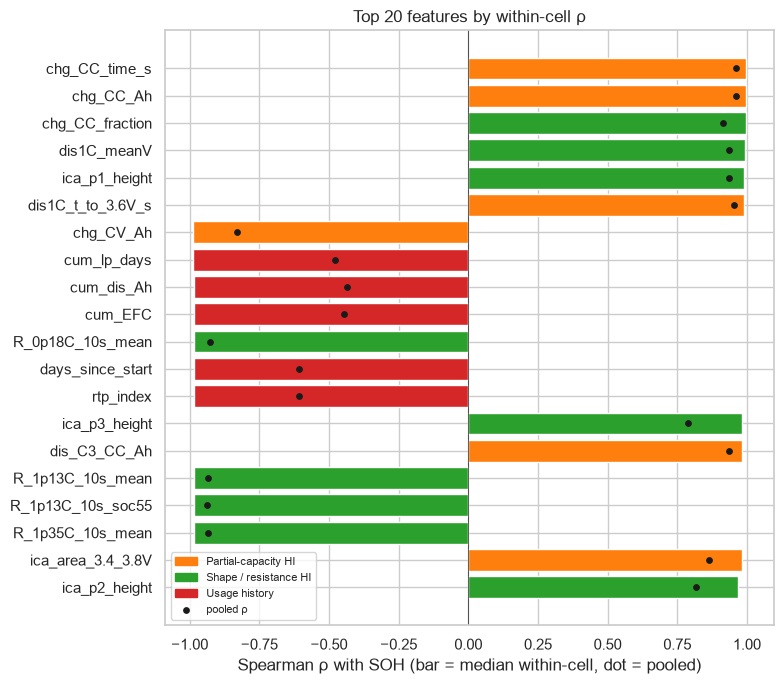

In [9]:
top = screen.dropna(subset=["within_cell_median"]).copy()
top["abs_within"] = top.within_cell_median.abs()
top = top.sort_values("abs_within", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 7))
pal = dict(zip(GROUPS, sns.color_palette("tab10", len(GROUPS))))
ax.barh(top.index[::-1], top.within_cell_median[::-1], color=[pal[g] for g in top.group[::-1]])
ax.scatter(top.pooled_spearman[::-1], top.index[::-1], c="k", s=15, zorder=3, label="pooled")
ax.axvline(0, c="k", lw=.5)
handles = [plt.Rectangle((0,0),1,1,color=pal[g]) for g in GROUPS if g in set(top.group)]
ax.legend(handles + [ax.collections[0]], [g for g in GROUPS if g in set(top.group)] + ["pooled ρ"], fontsize=8, loc="lower left")
ax.set(xlabel="Spearman ρ with SOH (bar = median within-cell, dot = pooled)", title="Top 20 features by within-cell ρ")
plt.tight_layout(); plt.savefig(FIG / "feature_screen_spearman.png", dpi=150); plt.show()

## 6. Redundancy between candidate features

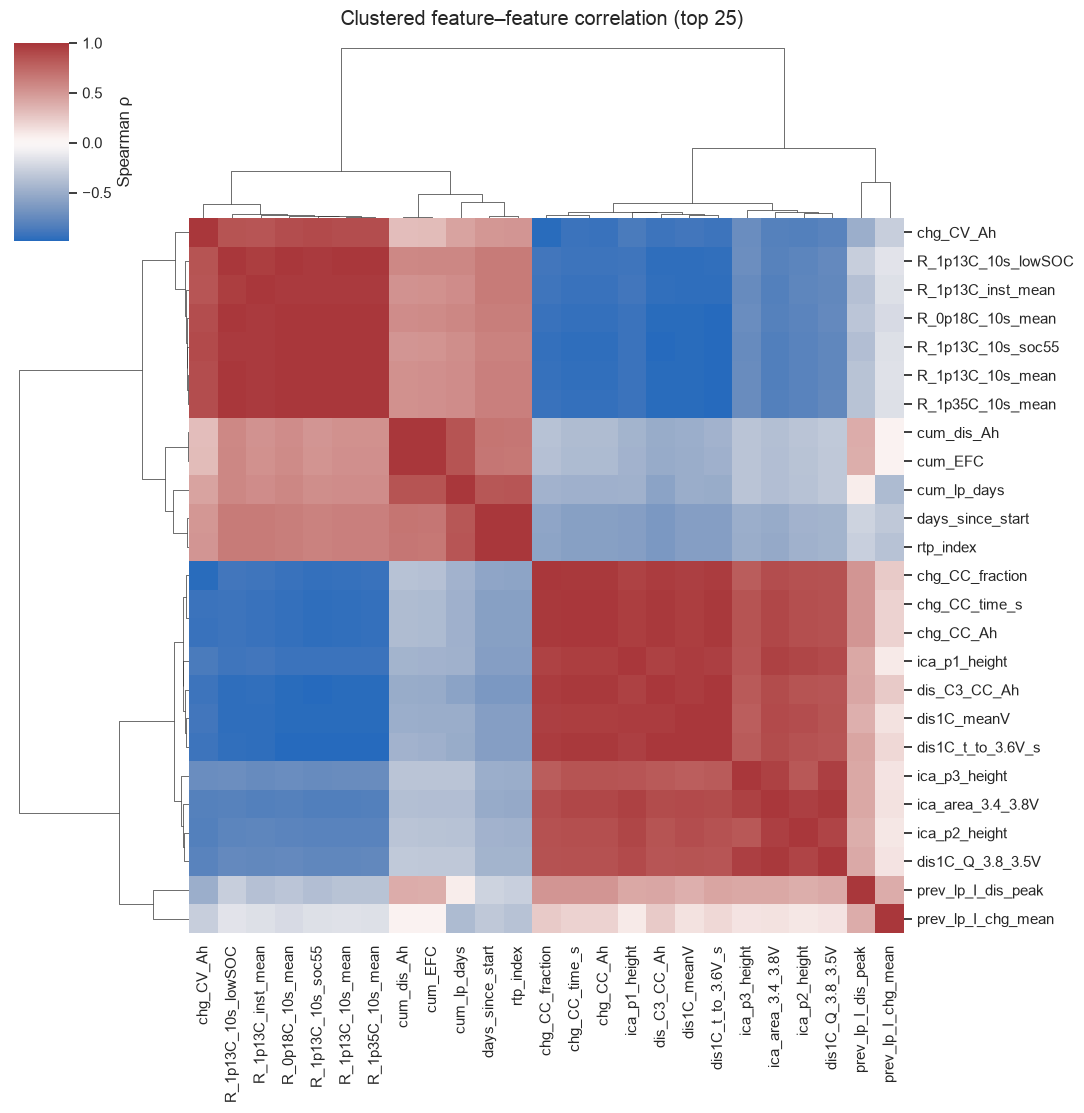

,level_0,level_1,rho
1,chg_CC_time_s,chg_CC_Ah,1.000
392,R_1p13C_10s_mean,R_1p35C_10s_mean,0.999
209,cum_dis_Ah,cum_EFC,0.999
265,R_0p18C_10s_mean,R_1p13C_10s_mean,0.999
267,R_0p18C_10s_mean,R_1p35C_10s_mean,0.999
391,R_1p13C_10s_mean,R_1p13C_10s_soc55,0.997
417,R_1p13C_10s_soc55,R_1p35C_10s_mean,0.996
266,R_0p18C_10s_mean,R_1p13C_10s_soc55,0.996
287,days_since_start,rtp_index,0.994
141,dis1C_t_to_3.6V_s,R_1p13C_10s_soc55,-0.986


In [10]:
cand = screen.dropna(subset=["within_cell_median"]).assign(a=lambda s: s.within_cell_median.abs()).sort_values("a", ascending=False).head(25).index
corr = df[cand].corr(method="spearman")
g = sns.clustermap(corr, cmap="vlag", center=0, figsize=(11, 11), annot=False, cbar_kws={"label": "Spearman ρ"})
g.fig.suptitle("Clustered feature–feature correlation (top 25)", y=1.01)
g.savefig(FIG / "feature_clustermap.png", dpi=150); plt.show()

# list pairs that are near-duplicates
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().rename("rho").reset_index()
            .query("abs(rho) > 0.95").sort_values("rho", key=abs, ascending=False))
display(pairs.head(20).round(3))

Blocks of |ρ| > 0.95 are **one feature in disguise**. Examples: all the `R_*` variants; the `cum_*` throughput and time
features within a profile; `chg_CC_time_s` and `chg_CC_Ah` (constant current, so time ∝ charge). Keep **one representative
per block**. That matters most for linear/ridge and SVR (multicollinearity), and less for random forest.

## 7. Which features survive an *unseen cell*? (group-aware screening)

Correlation isn't the same as generalization, so a quick model-based check follows. Random forest and ridge are trained on each
feature group with (a) a random row split and (b) **leave-cells-out** (GroupKFold by `cell_id`). The gap between
the two is the reliability question in the proposal. These are screening numbers, not final results.

In [11]:
def cv_scores(cols, groups_col="cell_id", n_splits=5, model="rf"):
    X, y, grp = df[cols], df.SOH.values, df[groups_col].values
    est = (make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(300, min_samples_leaf=2, random_state=0, n_jobs=-1))
           if model == "rf" else
           make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))))
    out = {}
    k = min(n_splits, len(np.unique(grp)))
    for name, cv, g in [("random", KFold(k, shuffle=True, random_state=0), None),
                        ("leave-cell-out", GroupKFold(k), grp)]:
        p = cross_val_predict(est, X, y, cv=cv, groups=g)
        out[f"MAE_{name}"] = mean_absolute_error(y, p); out[f"R2_{name}"] = r2_score(y, p)
    return out

sets = {
    "Usage history": GROUPS["Usage history"],
    "Usage + profile design": GROUPS["Usage history"] + GROUPS["Profile design"],
    "Usage + prev load period": GROUPS["Usage history"] + GROUPS["Previous load period"],
    "Shape/resistance HI": GROUPS["Shape / resistance HI"],
    "Partial-capacity HI": GROUPS["Partial-capacity HI"],
    "Shape HI + usage": GROUPS["Shape / resistance HI"] + GROUPS["Usage history"],
    "All non-leaky": FEATS,
}
res = []
base_mae = mean_absolute_error(df.SOH, np.full(len(df), df.SOH.mean()))
for name, cols in sets.items():
    for m in ["rf", "ridge"]:
        res.append(dict(feature_set=name, model=m, n_feats=len(cols), **cv_scores(cols, model=m)))
res = pd.DataFrame(res)
res["MAE_gap"] = res["MAE_leave-cell-out"] - res["MAE_random"]
print(f"Training-mean baseline MAE (in-sample, optimistic): {base_mae:.2f} SOH points")
display(res.round(3))

Training-mean baseline MAE (in-sample, optimistic): 7.86 SOH points


,feature_set,model,n_feats,MAE_random,R2_random,MAE_leave-cell-out,R2_leave-cell-out,MAE_gap
0,Usage history,rf,6,3.667,0.696,7.762,-0.260,4.096
1,Usage history,ridge,6,5.137,0.534,13.698,-5.976,8.561
2,Usage + profile design,rf,13,1.874,0.862,5.902,0.161,4.028
3,Usage + profile design,ridge,13,3.639,0.754,8.428,-0.625,4.789
4,Usage + prev load period,rf,16,1.798,0.857,5.735,0.216,3.937
5,Usage + prev load period,ridge,16,3.802,0.741,8.021,-0.833,4.219
6,Shape/resistance HI,rf,19,1.283,0.962,1.861,0.934,0.578
7,Shape/resistance HI,ridge,19,1.071,0.983,1.753,0.943,0.682
8,Partial-capacity HI,rf,7,1.127,0.970,1.499,0.951,0.372
9,Partial-capacity HI,ridge,7,0.686,0.993,0.866,0.990,0.181


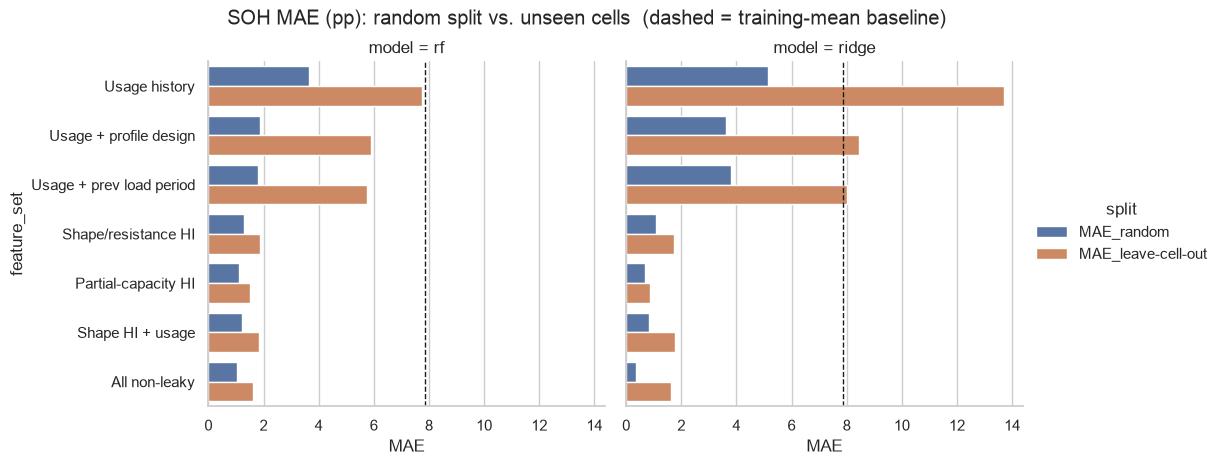

In [12]:
plot = res.melt(id_vars=["feature_set", "model"], value_vars=["MAE_random", "MAE_leave-cell-out"],
                var_name="split", value_name="MAE")
g = sns.catplot(data=plot, y="feature_set", x="MAE", hue="split", col="model", kind="bar", height=4.5, aspect=1.2)
for ax in g.axes.flat: ax.axvline(base_mae, c="k", ls="--", lw=1)
g.fig.suptitle("SOH MAE (pp): random split vs. unseen cells  (dashed = training-mean baseline)", y=1.03)
g.savefig(FIG / "random_vs_groupcv_by_featureset.png", dpi=150); plt.show()

### 7b. Permutation importance under leave-cell-out

,mean_MAE_increase,folds_positive,group
chg_CC_V0,1.768,5.0,Shape / resistance HI
chg_CC_time_s,1.396,5.0,Partial-capacity HI
chg_CC_Ah,1.100,5.0,Partial-capacity HI
dis1C_t_to_3.6V_s,0.441,5.0,Partial-capacity HI
ica_p1_height,0.162,5.0,Shape / resistance HI
ica_p3_height,0.155,4.0,Shape / resistance HI
cum_lp_T_mean,0.045,4.0,Usage history
R_1p13C_10s_soc55,0.037,4.0,Shape / resistance HI
prev_lp_T_max,0.032,4.0,Previous load period
dis1C_meanV,0.023,4.0,Shape / resistance HI


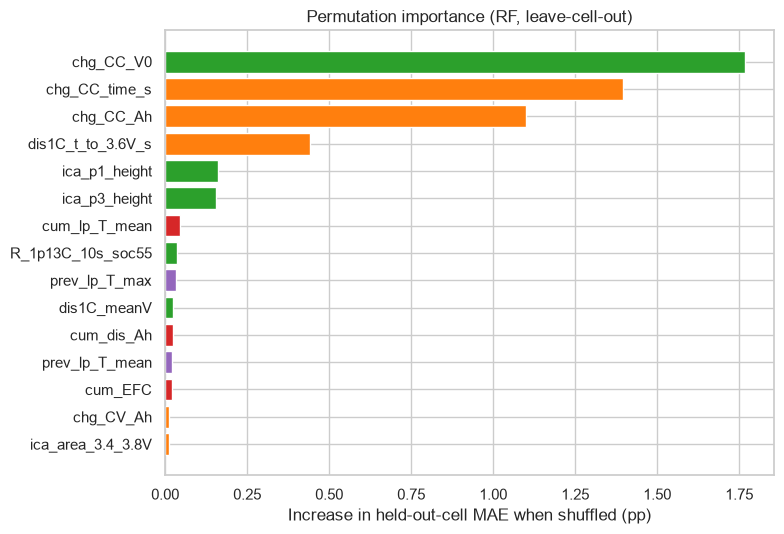

In [13]:
X, y, grp = df[FEATS], df.SOH.values, df.cell_id.values
imp_rows = []
for tr, te in GroupKFold(min(5, df.cell_id.nunique())).split(X, y, grp):
    est = make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(300, min_samples_leaf=2, random_state=0, n_jobs=-1))
    est.fit(X.iloc[tr], y[tr])
    pi = permutation_importance(est, X.iloc[te], y[te], n_repeats=10, random_state=0, scoring="neg_mean_absolute_error")
    imp_rows.append(pd.Series(pi.importances_mean, index=FEATS))
imp = pd.concat(imp_rows, axis=1)
imp_summary = pd.DataFrame({"mean_MAE_increase": imp.mean(1), "folds_positive": (imp > 0).sum(1),
                            "group": pd.Series(group_of)}).sort_values("mean_MAE_increase", ascending=False)
display(imp_summary.head(20).round(3))

top15 = imp_summary.head(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top15.index[::-1], top15.mean_MAE_increase[::-1], color=[pal[g] for g in top15.group[::-1]])
ax.set(xlabel="Increase in held-out-cell MAE when shuffled (pp)", title="Permutation importance (RF, leave-cell-out)")
plt.tight_layout(); plt.savefig(FIG / "permutation_importance_groupcv.png", dpi=150); plt.show()

Features with a high mean importance **and** positive importance in every fold are the ones to keep.
A feature that only helps in one fold is fitting a single cell's quirks.

**Caveat on `chg_CC_V0`.** It is the rested voltage at the start of the C/2 charge, i.e. *after a full 1C discharge
to 2.5 V and a 30-min rest*. It carries information about how deep the cell was emptied (a capacity proxy), so treat it as
a partial-capacity-type feature, not a pure "shape" feature, and check results without it.

## 8. Profile-level shift: are unseen operating conditions inside the training range?

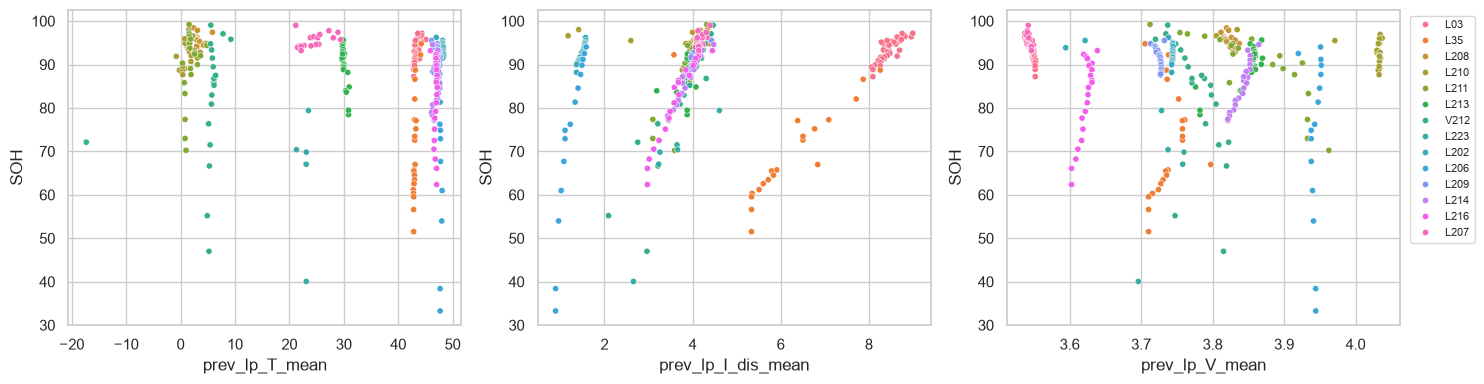

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, x in zip(axes, ["prev_lp_T_mean", "prev_lp_I_dis_mean", "prev_lp_V_mean"]):
    sns.scatterplot(data=df, x=x, y="SOH", hue="profile", ax=ax, s=20, legend=(ax is axes[-1]))
axes[-1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "operating_conditions_vs_soh.png", dpi=150); plt.show()

Each profile sits in its own corner of operating-condition space. When a whole profile is held out, a tree model
**cannot extrapolate** beyond the temperatures and currents it has seen. Choose held-out profiles that lie *inside* the
training range (interpolation) and, separately, at the edge (extrapolation), and report both. This gives the
"when does performance decrease" result the proposal asks for.

## 9. Summary: recommended feature set

In [15]:
summary = screen.join(imp_summary[["mean_MAE_increase", "folds_positive"]])
summary["keep"] = ((summary.within_cell_median.abs() >= 0.6) & (summary.sign_consistency >= 0.8)) | \
                  ((summary.mean_MAE_increase > 0) & (summary.folds_positive >= 4))
display(summary[summary.keep].sort_values(["group", "mean_MAE_increase"], ascending=[True, False])
        [["group", "within_cell_median", "sign_consistency", "pooled_spearman", "mean_MAE_increase", "folds_positive"]].round(3))
summary.round(4).to_csv(ROOT / "results" / "feature_screening_summary.csv")

,group,within_cell_median,sign_consistency,pooled_spearman,mean_MAE_increase,folds_positive
feature,,,,,,
chg_CC_time_s,Partial-capacity HI,0.998,1.000,0.962,1.396,5.0
chg_CC_Ah,Partial-capacity HI,0.998,1.000,0.961,1.100,5.0
dis1C_t_to_3.6V_s,Partial-capacity HI,0.991,1.000,0.954,0.441,5.0
chg_CV_Ah,Partial-capacity HI,-0.989,1.000,-0.830,0.012,3.0
ica_area_3.4_3.8V,Partial-capacity HI,0.982,0.933,0.863,0.012,2.0
dis_C3_CC_Ah,Partial-capacity HI,0.983,1.000,0.937,0.012,3.0
dis1C_Q_3.8_3.5V,Partial-capacity HI,0.949,0.933,0.794,0.008,2.0
prev_lp_T_max,Previous load period,0.000,0.067,-0.362,0.032,4.0
prev_lp_T_mean,Previous load period,0.314,0.867,-0.250,0.020,4.0


#EDA Findings

DataSet: Our subset has 15 cells under 14 load profiles, with 306 labelled rows. Each row is one 25 °C reference test, and each cell has only 6–23 labels. Rows from one cell are strongly correlated, so the real sample size is 15 cells, not 306. Most profiles belong to a single cell, so unseen-cell and unseen-profile tests are nearly the same, and degradation varies widely (final SOH 33–93%).

Target Variable:
SOH is measured only at 25 °C, because test temperature changes capacity by about 13%.
Health classes: Healthy (above 90%), Degraded (80–90%), and EOL-risk (below 80%).
Class counts are 187, 66, and 53, and the EOL-risk class comes from only 8 cells.





